In [1]:
import pandas as pd

# Create the dataset
data = {
    "YearsExperience": [
        1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5
    ],
    "Salary": [
        39343.00, 46205.00, 37731.00, 43525.00, 39891.00, 56642.00,
        60150.00, 54445.00, 64445.00, 57189.00, 63218.00, 55794.00,
        56957.00, 57081.00, 61111.00, 67938.00, 66029.00, 83088.00,
        81363.00, 93940.00, 91738.00, 98273.00, 101302.00, 113812.00,
        109431.00, 105582.00, 116969.00, 112635.00, 122391.00, 121872.00
    ]
}

# Save to CSV
df = pd.DataFrame(data)
df.to_csv("salary_data.csv", index=False)
print("✅ salary_data.csv created successfully!")


✅ salary_data.csv created successfully!


Epoch [200/1000], Loss: 499167104.0000
Epoch [400/1000], Loss: 170835536.0000
Epoch [600/1000], Loss: 150418928.0000
Epoch [800/1000], Loss: 147174032.0000
Epoch [1000/1000], Loss: 144923136.0000


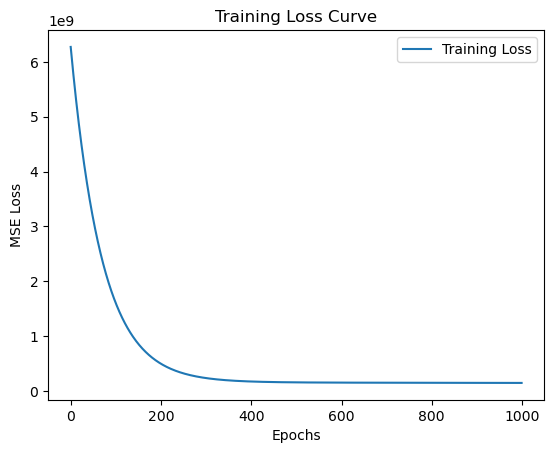

Learned Weight: 12729.2119, Bias: 2967.6187


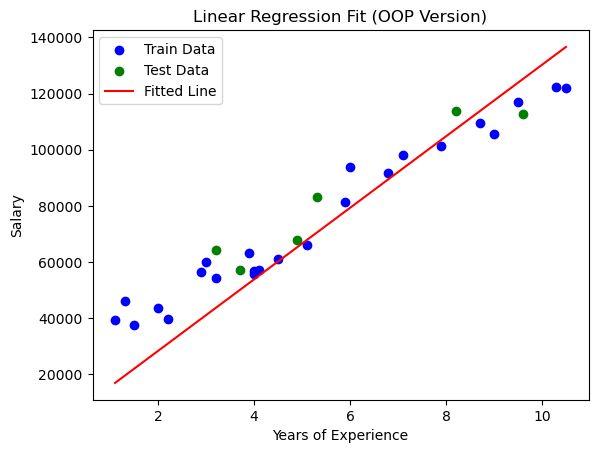

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ===============================
# Linear Regression using OOP
# ===============================
class LinearRegressionModel(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LinearRegressionModel, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)  # y = Wx + b

    def forward(self, x):
        return self.linear(x)

class Trainer:
    def __init__(self, model, criterion, optimizer):
        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer
        self.losses = []

    def train(self, X_train, y_train, epochs=1000, log_interval=200):
        for epoch in range(epochs):
            # Forward pass
            outputs = self.model(X_train)
            loss = self.criterion(outputs, y_train)

            # Backward pass (Gradient Descent)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()

            self.losses.append(loss.item())

            if (epoch+1) % log_interval == 0:
                print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

    def plot_loss(self):
        plt.plot(range(len(self.losses)), self.losses, label="Training Loss")
        plt.xlabel("Epochs")
        plt.ylabel("MSE Loss")
        plt.title("Training Loss Curve")
        plt.legend()
        plt.show()

# ===============================
# Main Execution
# ===============================
def main():
    # Load dataset
    data = pd.read_csv("salary_data.csv")

    # Convert to tensors
    X = torch.tensor(data["YearsExperience"].values, dtype=torch.float32).view(-1, 1)
    y = torch.tensor(data["Salary"].values, dtype=torch.float32).view(-1, 1)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Model, Loss, Optimizer
    model = LinearRegressionModel(input_dim=1, output_dim=1)
    criterion = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.0001)

    # Train the model
    trainer = Trainer(model, criterion, optimizer)
    trainer.train(X_train, y_train, epochs=1000)
    trainer.plot_loss()

    # Print learned parameters
    w, b = model.parameters()
    print(f"Learned Weight: {w.item():.4f}, Bias: {b.item():.4f}")

    # Plot regression line
    plt.scatter(X_train.numpy(), y_train.numpy(), label="Train Data", color="blue")
    plt.scatter(X_test.numpy(), y_test.numpy(), label="Test Data", color="green")
    plt.plot(X.numpy(), model(X).detach().numpy(), color="red", label="Fitted Line")
    plt.xlabel("Years of Experience")
    plt.ylabel("Salary")
    plt.title("Linear Regression Fit (OOP Version)")
    plt.legend()
    plt.show()

    # Interactive prediction
    while True:
        try:
            years = float(input("Enter years of experience (or -1 to exit): "))
            if years == -1:
                print("Exiting...")
                break
            new_exp = torch.tensor([[years]], dtype=torch.float32)
            predicted_salary = model(new_exp).item()
            print(f"Predicted salary for {years} years experience: {predicted_salary:.2f}")

            # Visualization
            plt.scatter(X.numpy(), y.numpy(), label="Dataset", color="blue")
            plt.plot(X.numpy(), model(X).detach().numpy(), color="red", label="Fitted Line")
            plt.scatter(years, predicted_salary, color="orange", s=100, label="Prediction")
            plt.xlabel("Years of Experience")
            plt.ylabel("Salary")
            plt.title(f"Prediction for {years} Years Experience")
            plt.legend()
            plt.show()

        except:
            print("Please enter a valid number.")

if __name__ == "__main__":
    main()
